In [30]:
from MACDFuncs import *
from MACDUtils import *
from MACDcalculators import *
from lasttest import *
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.style.use("plot_style.txt")
# from os import listdir

from termcolor import colored as cl
from math import floor

# plt.rcParams['figure.figsize'] = (20, 10)
# plt.style.use('fivethirtyeight')


# alphaRange = [-0.9, -0.8, -0.5, -0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.8, 0.9]
# gammaRange = [10, 100, 1000, 10000, 100000, 1000000]


alphaRange = [-0.9, -0.5, -0.1, 0, 0.1, 0.5, 0.9]
gammaRange = [10, 100, 1000]
histogramList, MACDList = return_MACDLists(alphaRange, gammaRange)


def return_macd_crossover_results(histogramList, df, timeFormat, market):
    l = []
    bets_list_dict = {}
    for his in histogramList:
        (
            net,
            netbet,
            netpercent,
            bets,
            wins,
            longs,
            long_wins,
            long_profit,
            shorts,
            short_wins,
            short_profit,
            bets_list,
        ) = macd_crossover(
            df,
            "close",
            his,
            timeFormat,
            market,
            ballance=20000,
            riskPerTrade=50 / 100,
            trade_cost=False,
            signalLineIF=False,
            above200EMAIF=False,
        )
        l.append(
            [
                net,
                netbet,
                netpercent,
                bets,
                wins,
                longs,
                long_wins,
                long_profit,
                shorts,
                short_wins,
                short_profit,
                his,
            ]
        )
        bets_list_dict[his] = bets_list
    dff = pd.DataFrame(
        data=l,
        columns=[
            "net",
            "netbet",
            "netpercent",
            "bets",
            "wins",
            "longs",
            "long_wins",
            "long_profit",
            "shorts",
            "short_wins",
            "short_profit",
            "his",
        ],
    )
    dff.drop([0], inplace=True)
    dff.reset_index(inplace=True)
    dff.drop(columns=["index"], inplace=True)
    return dff, bets_list_dict


def return_macdn_data_for_plot(his_mode, current_df):
    if his_mode == "Histogram":
        signal_line = "SignalLine"
        macd_line = "MACD"
    else:
        his_words = his_mode.split(" ")
        if len(his_words) == 5:
            macd_line = (" ").join(["MACDN2", *his_words[1:]])
            signal_line = (" ").join(["MACDN2 Signal", *his_words[1:]])
        else:
            macd_line = (" ").join(["MACDN1", *his_words[1:]])
            signal_line = (" ").join(["MACDN1 Signal", *his_words[1:]])

    macd = current_df[macd_line]
    signal = current_df[signal_line]
    hist = current_df[his_mode]

    return macd, signal, hist


def get_actions_prices(bets_dict, his_mode, current_df):
    position_prices, actions = [bet[0] for bet in bets_dict[his_mode]], [
        bet[1] for bet in bets_dict[his_mode]
    ]
    close_data_list = list(current_df["close"])

    buy_price = [np.nan for i in range(len(close_data_list))]
    sell_price = [np.nan for i in range(len(close_data_list))]

    for i in range(0, len(actions), 2):
        position_mode = actions[i].split(" ")[1]
        price_index = close_data_list.index(position_prices[i])

        if position_mode == "Long":
            buy_price[price_index] = position_prices[i]
        else:
            sell_price[price_index] = position_prices[i]

    return buy_price, sell_price

In [31]:
market = "stocks"
trade_cost = False
timeFormat = "Hourly"
prefix = f"./data/{market}/{timeFormat}/"
if timeFormat == "Daily":
    datafiles = listdir(prefix)
else:
    datafiles = listdir(prefix + "1/")
datafiles

['msft.us.txt',
 'nflx.us.txt',
 'googl.us.txt',
 'amzn.us.txt',
 'aapl.us.txt',
 'fb.us.txt']

In [32]:
tick = "msft.us.txt"
tick_dict = {key: key.split(".")[0].upper() for key in datafiles}
df = makeDataFrame(prefix, tick, timeFormat, alphaRange, gammaRange)
df

,ticker,open,high,low,close,volume,MACD,SignalLine,Histogram,ema 200,...,Histogram a: 0.9 g: 10,MACDN2 a: 0.9 g: 10 times,MACDN2 a: 0.9 g: 100,MACDN2 Signal a: 0.9 g: 100,Histogram a: 0.9 g: 100,MACDN2 a: 0.9 g: 100 times,MACDN2 a: 0.9 g: 1000,MACDN2 Signal a: 0.9 g: 1000,Histogram a: 0.9 g: 1000,MACDN2 a: 0.9 g: 1000 times
2020-03-27 18:00:00,msft,150.11,151.23,149.44,151.010,3336251,2.049269,2.343508,-0.294239,157.909650,...,0.426659,78,1.894295,1.473910,0.420385,1334,1.892938,1.473634,0.419304,3229
2020-03-27 19:00:00,msft,151.02,152.60,150.69,151.880,4076855,2.015461,2.277899,-0.262438,157.849653,...,0.351667,78,1.911981,1.561525,0.350456,1334,1.908571,1.560621,0.347950,3229
2020-03-27 20:00:00,msft,151.89,153.30,151.51,152.760,4321075,2.036204,2.229560,-0.193356,157.799010,...,0.290416,78,1.922239,1.633667,0.288571,1334,1.919260,1.632349,0.286911,3229
2020-03-27 21:00:00,msft,152.74,153.69,148.10,148.530,17161642,1.691816,2.122011,-0.430195,157.706781,...,0.222730,78,1.930876,1.693109,0.237767,1334,1.930954,1.692070,0.238884,3229
2020-03-30 16:00:00,msft,151.25,155.70,148.84,154.860,8016238,1.907673,2.079143,-0.171471,157.678455,...,0.169902,78,1.907104,1.735908,0.171196,1334,1.907104,1.735077,0.172027,3229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-09-29 18:00:00,msft,285.20,285.25,283.48,284.091,1542845,-3.460200,-2.978510,-0.481691,296.013859,...,-0.660876,78,-2.032062,-1.371227,-0.660836,1334,-2.032062,-1.371243,-0.660820,3229
2021-09-29 19:00:00,msft,284.13,284.43,283.01,283.960,1514106,-3.453269,-3.073462,-0.379807,295.893920,...,-0.642952,78,-2.174876,-1.531957,-0.642919,1334,-2.174876,-1.531969,-0.642907,3229
2021-09-29 20:00:00,msft,283.98,285.29,283.56,284.800,1711454,-3.341476,-3.127064,-0.214411,295.783532,...,-0.616635,78,-2.302715,-1.686109,-0.616607,1334,-2.302715,-1.686119,-0.616597,3229
2021-09-29 21:00:00,msft,284.81,286.77,284.75,286.270,1959690,-3.098544,-3.121360,0.022816,295.688870,...,-0.576868,78,-2.406592,-1.830205,-0.576386,1334,-2.406592,-1.830213,-0.576378,3229


In [33]:
if timeFormat == "Hourly":
    start = df.iloc[0].name
    end = makeNewTime(start, 4, "week")
else:
    start = df.iloc[0].name
    end = makeNewTime(start, 1, "day")
df_subset = df[start:end]
# df_subset = df
ind = [str(i) for i in df_subset.index]
prices = df_subset["close"]
df_subset

,ticker,open,high,low,close,volume,MACD,SignalLine,Histogram,ema 200,...,Histogram a: 0.9 g: 10,MACDN2 a: 0.9 g: 10 times,MACDN2 a: 0.9 g: 100,MACDN2 Signal a: 0.9 g: 100,Histogram a: 0.9 g: 100,MACDN2 a: 0.9 g: 100 times,MACDN2 a: 0.9 g: 1000,MACDN2 Signal a: 0.9 g: 1000,Histogram a: 0.9 g: 1000,MACDN2 a: 0.9 g: 1000 times
2020-03-27 18:00:00,msft,150.11,151.23,149.44,151.01,3336251,2.049269,2.343508,-0.294239,157.909650,...,0.426659,78,1.894295,1.473910,0.420385,1334,1.892938,1.473634,0.419304,3229
2020-03-27 19:00:00,msft,151.02,152.60,150.69,151.88,4076855,2.015461,2.277899,-0.262438,157.849653,...,0.351667,78,1.911981,1.561525,0.350456,1334,1.908571,1.560621,0.347950,3229
2020-03-27 20:00:00,msft,151.89,153.30,151.51,152.76,4321075,2.036204,2.229560,-0.193356,157.799010,...,0.290416,78,1.922239,1.633667,0.288571,1334,1.919260,1.632349,0.286911,3229
2020-03-27 21:00:00,msft,152.74,153.69,148.10,148.53,17161642,1.691816,2.122011,-0.430195,157.706781,...,0.222730,78,1.930876,1.693109,0.237767,1334,1.930954,1.692070,0.238884,3229
2020-03-30 16:00:00,msft,151.25,155.70,148.84,154.86,8016238,1.907673,2.079143,-0.171471,157.678455,...,0.169902,78,1.907104,1.735908,0.171196,1334,1.907104,1.735077,0.172027,3229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-04-23 18:00:00,msft,173.28,173.31,171.95,172.22,3195356,0.087829,-0.301197,0.389026,164.169657,...,-0.231833,78,-0.094277,0.147948,-0.242225,1334,-0.094924,0.147739,-0.242664,3229
2020-04-23 19:00:00,msft,172.22,172.87,169.59,171.57,3617701,0.075021,-0.225953,0.300975,164.243292,...,-0.171675,78,-0.075129,0.103333,-0.178462,1334,-0.076649,0.102861,-0.179511,3229
2020-04-23 20:00:00,msft,171.56,172.24,170.08,170.53,3085245,-0.018831,-0.184529,0.165698,164.305847,...,-0.131496,78,-0.057926,0.071081,-0.129007,1334,-0.060790,0.070131,-0.130921,3229
2020-04-23 21:00:00,msft,170.52,171.82,169.79,171.80,3013529,0.009163,-0.145791,0.154954,164.380415,...,-0.100054,78,-0.052945,0.046276,-0.099220,1334,-0.057136,0.044678,-0.101814,3229


In [34]:
# ['Histogram', 'Histogram a: -0.9', 'Histogram a: -0.5', 'Histogram a: -0.4', 'Histogram a: -0.3',
# 'Histogram a: -0.2', 'Histogram a: -0.1', 'Histogram a: 0', 'Histogram a: 0.1', 'Histogram a: 0.2',
# 'Histogram a: 0.3', 'Histogram a: 0.4', 'Histogram a: 0.5', 'Histogram a: 0.9', 'Histogram a: -0.9 g: 10',
# 'Histogram a: -0.9 g: 100', 'Histogram a: -0.5 g: 10', 'Histogram a: -0.5 g: 100', 'Histogram a: -0.4 g: 10',
# 'Histogram a: -0.4 g: 100', 'Histogram a: -0.3 g: 10', 'Histogram a: -0.3 g: 100',
# 'Histogram a: -0.2 g: 10', 'Histogram a: -0.2 g: 100', 'Histogram a: -0.1 g: 10',
# 'Histogram a: -0.1 g: 100', 'Histogram a: 0 g: 10', 'Histogram a: 0 g: 100',
# 'Histogram a: 0.1 g: 10', 'Histogram a: 0.1 g: 100', 'Histogram a: 0.2 g: 10',
# 'Histogram a: 0.2 g: 100', 'Histogram a: 0.3 g: 10', 'Histogram a: 0.3 g: 100',
# 'Histogram a: 0.4 g: 10', 'Histogram a: 0.4 g: 100', 'Histogram a: 0.5 g: 10',
# 'Histogram a: 0.5 g: 100', 'Histogram a: 0.9 g: 10', 'Histogram a: 0.9 g: 100']

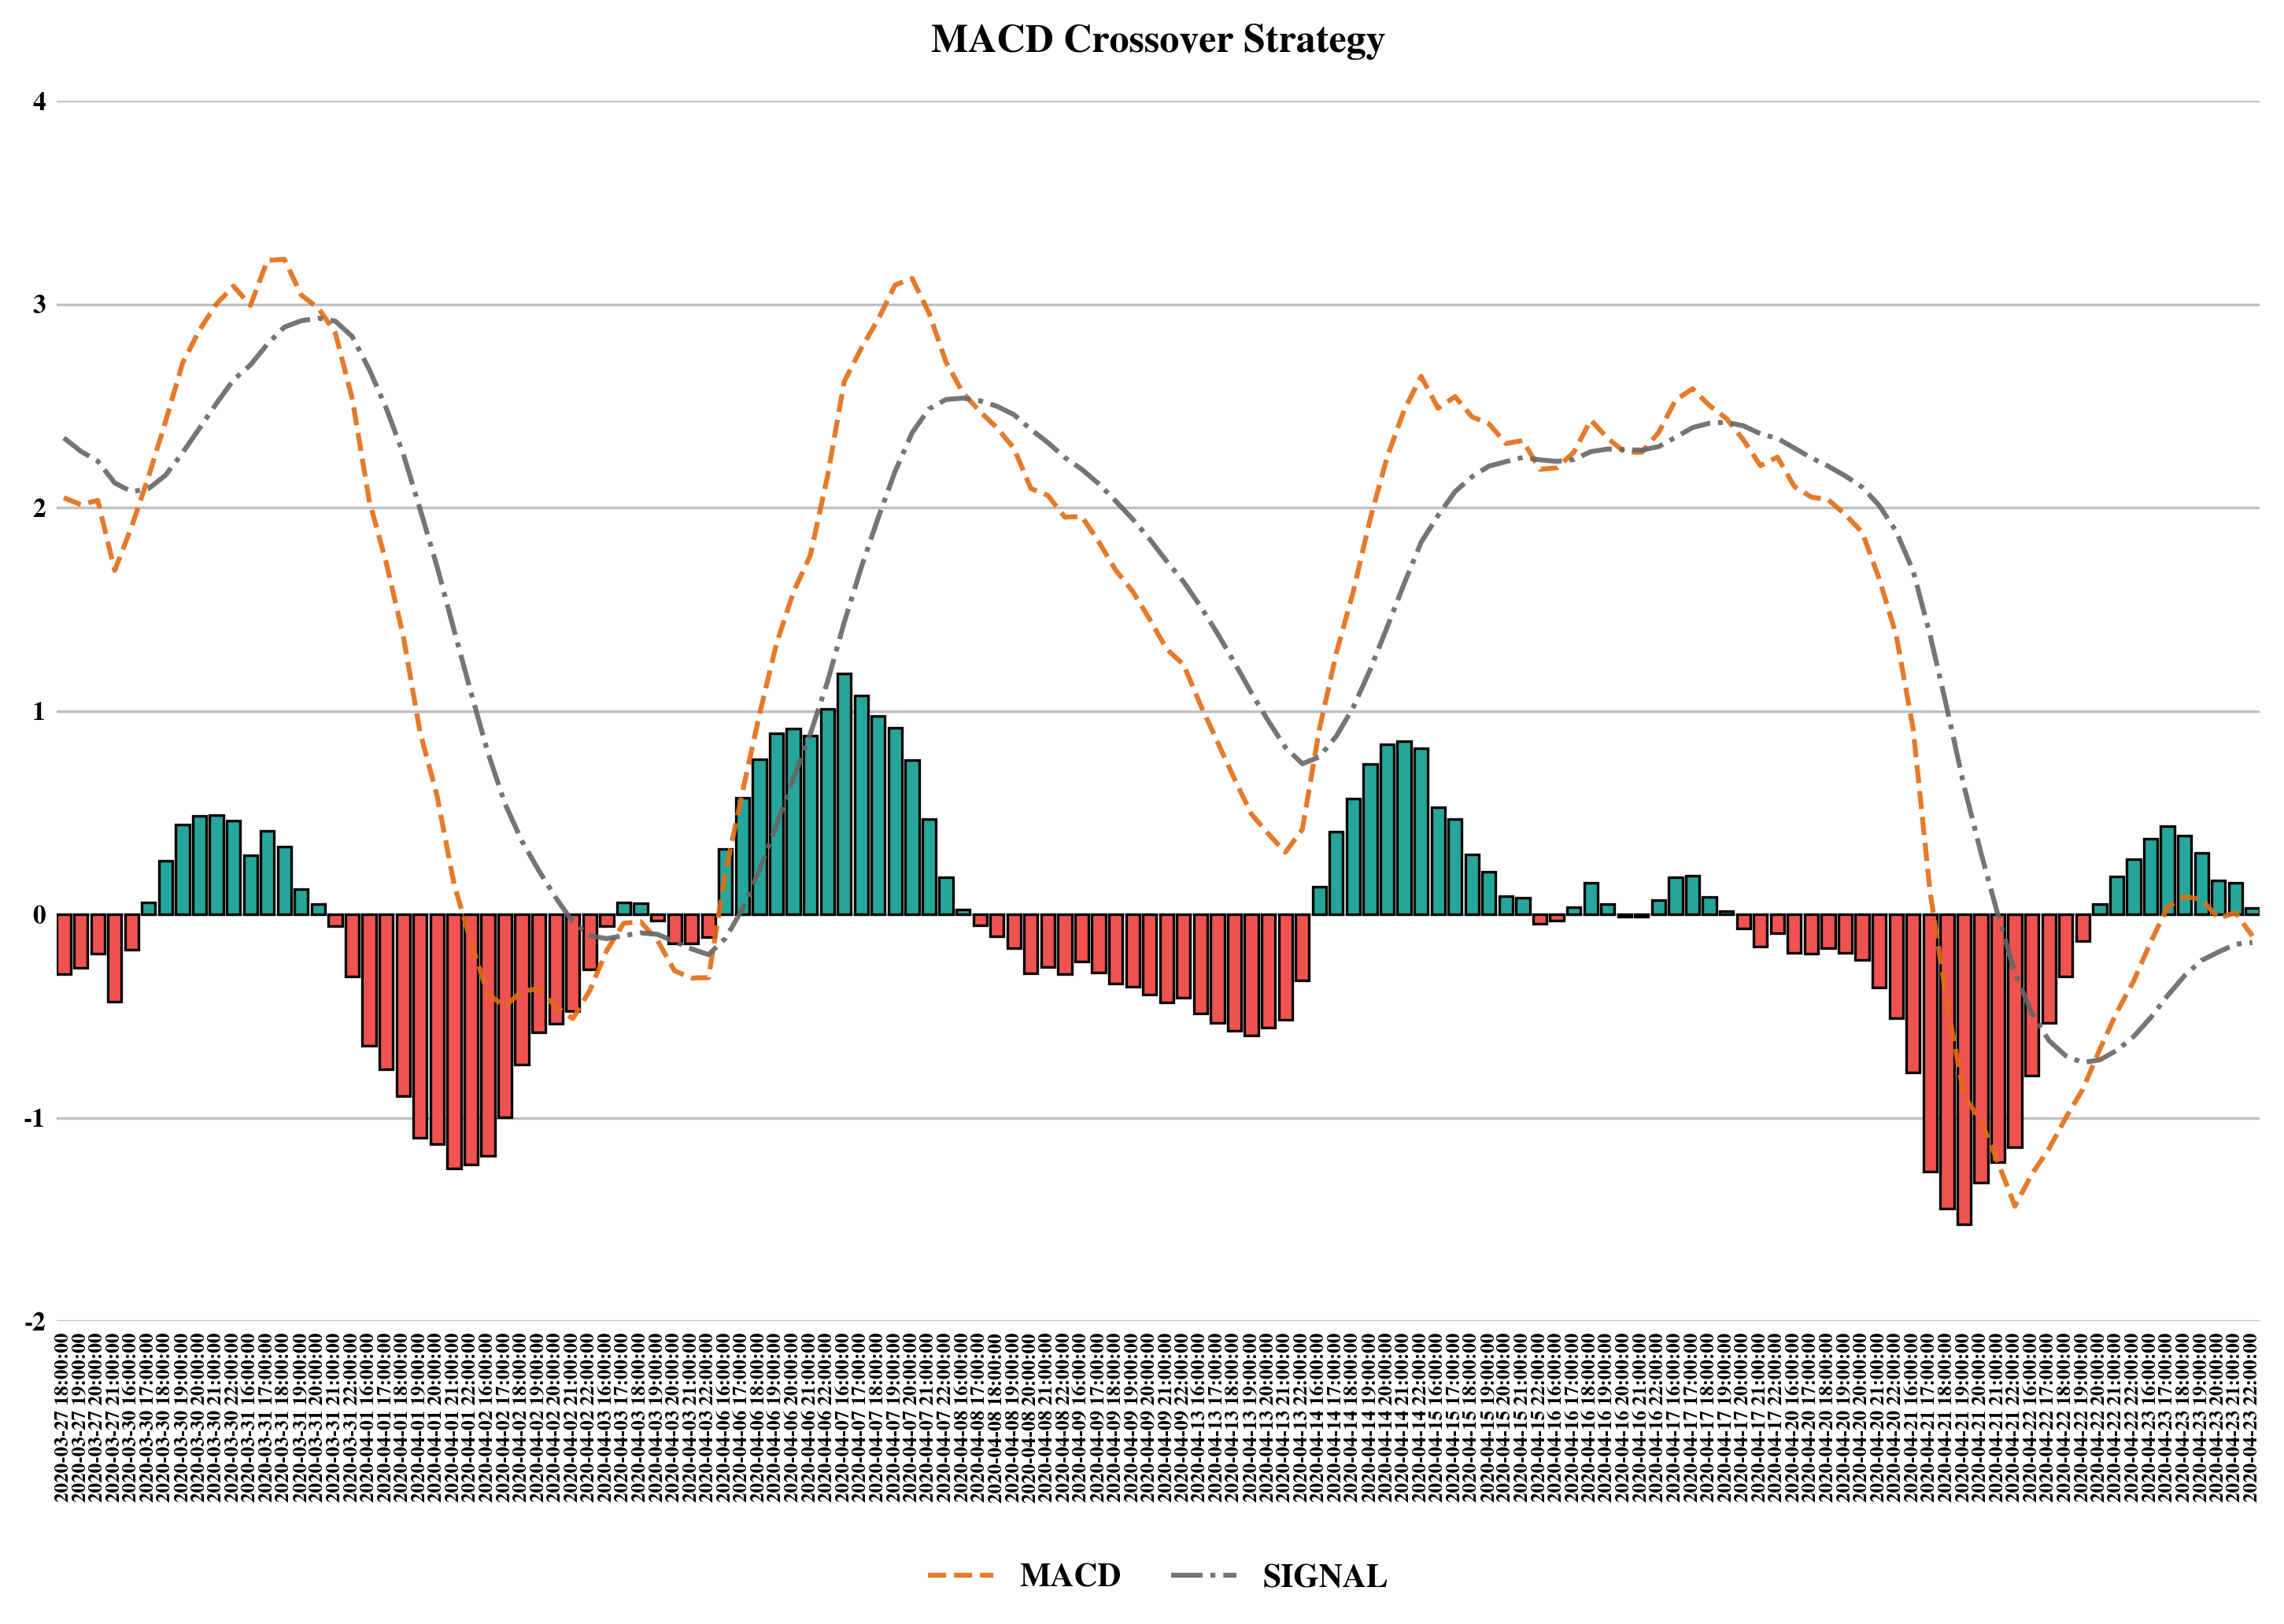

In [35]:
his_mode = "Histogram"
# Histogram - amzn - showing how macd cross is done
macd, signal, hist = return_macdn_data_for_plot(his_mode, df_subset)
dff, bets = return_macd_crossover_results(histogramList, df_subset, timeFormat, market)

fig, ax = plt.subplots()

ax.plot(
    ind, macd, color="#e36c14", linewidth=1.5, label="MACD", linestyle="--", alpha=0.9
)
ax.plot(
    ind,
    signal,
    color="#666667",
    linewidth=1.5,
    label="SIGNAL",
    linestyle="-.",
    alpha=0.9,
)

for i in range(len(hist)):
    if str(hist[i])[0] == "-":
        ax.bar(ind[i], hist[i], color="#ef5350")
    else:
        ax.bar(ind[i], hist[i], color="#26a69a")

ax.ticklabel_format(axis="y", style="plain")

ax.xaxis.set_ticks(ind)
ax.set_xticklabels(ind, weight="bold", color="black")

avg_y_ticks = list(ax.get_yticks())
if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = int(avg_y_ticks[i])
else:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = round(avg_y_ticks[i], 1)
# print(plt.yticks())
# print(ax.get_yticks())
# print(ax.get_yticklines())
# print(ax.get_yticklabels())
# print(ax.get_ymajorticklabels())

ax.yaxis.set_ticks(avg_y_ticks)
ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

plt.rcParams["font.weight"] = "bold"

ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_axisbelow(True)
ax.tick_params(axis="both", which="both", length=0)
plt.xticks(rotation=90)

# ax.xaxis.grid(alpha = 0.15)
ax.yaxis.grid(alpha=0.8)
# mpl.rcParams['axes.linewidth'] = 3

ax.margins(0)

fig.tight_layout()

fig.set_size_inches(10, 7)

ax.legend(
    labelcolor="black",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
)
t = ax.set_title(
    "MACD Crossover Strategy",
    loc="center",
    pad=15,
    size=12,
    fontweight="bold",
    color="black",
)


plt.savefig(f"MACD_Crossover_Strategy.pdf", bbox_inches="tight")

In [36]:
def plot_macds_subplot(
    his_mode, df_subset, histogramList, data_price, ax, ind, axIndex=None
):
    macd, signal, hist = return_macdn_data_for_plot(his_mode, df_subset)

    ax.plot(
        ind,
        macd,
        color="#e36c14",
        linewidth=1.5,
        label="MACD",
        linestyle="--",
        alpha=0.9,
    )
    ax.plot(
        ind,
        signal,
        color="#666667",
        linewidth=1.5,
        label="SIGNAL",
        linestyle="-.",
        alpha=0.9,
    )

    # for i in range(len(hist)):
    #     if str(hist[i])[0] == '-':
    #         ax.bar(ind[i], hist[i], color = '#ef5350')
    #     else:
    #         ax.bar(ind[i], hist[i], color = '#26a69a')

    # for i in range(len(hist)):
    #     if str(hist[i])[0] == '-':
    #         ax.bar(ind[i], 0.3, color = '#ef5350')
    #     else:
    #         ax.bar(ind[i], 0.3, color = '#26a69a')

    ax.ticklabel_format(axis="y", style="plain")

    ax.xaxis.set_ticks(ind)
    ax.set_xticklabels(ind, weight="bold", color="black")

    if axIndex == 2:
        ax.xaxis.set_ticks(ind)
        ax.set_xticklabels(ind, weight="bold", color="black", fontsize=5.5)

    avg_y_ticks = list(ax.get_yticks())
    # print(ax.get_yticks())
    if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
        for i in range(len(avg_y_ticks)):
            avg_y_ticks[i] = int(avg_y_ticks[i])
    # print(avg_y_ticks)

    ax.yaxis.set_ticks(avg_y_ticks)
    ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
    ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

    # ax.spines["left"].set_visible(True)
    # ax.spines["right"].set_visible(True)
    # ax.spines["bottom"].set_visible(False)
    # # mpl.rcParams['axes.linewidth'] = 3
    ax.spines["right"].set_visible(True)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["top"].set_visible(True)

    ax.set_axisbelow(True)
    ax.tick_params(axis="both", which="both", length=0)
    plt.xticks(rotation=90)

    # ax.xaxis.grid(alpha = 0.15)
    ax.yaxis.grid(alpha=0.8)

    ax.margins(0.01)

    if axIndex == 2:
        ax.legend(
            labelcolor="black",
            loc="upper center",
            bbox_to_anchor=(0.5, -0.6),
            ncol=2,
            frameon=False,
            fontsize=8,
        )

    # increasing y makes it go up, decreasing y makes it go down
    if his_mode == "Histogram":
        his_title = r"$\alpha: 0$"
        t = ax.set_title(
            f"{his_title}",
            loc="right",
            y=0.38,
            size=8,
            x=1.0125,
            fontweight="bold",
            color="black",
            rotation=-90,
        )

    else:

        his_words = his_mode.split(" ")

        if len(his_words) == 5:  # MACDN2

            if float(his_words[2]) > 0:  # a > 0

                if int(his_words[4]) == 10:  # g = 10
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.062,
                        size=6,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

                else:  # g = 100
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.12,
                        size=6,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

            else:  # a < 0

                if int(his_words[4]) == 10:  # g = 10
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.117,
                        size=5.5,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

                else:  # g = 100
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.115,
                        size=5,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

        else:  # MACDN1

            if float(his_words[2]) > 0:
                his_title = r"$\alpha: " + his_words[2] + "$"
                t = ax.set_title(
                    f"{his_title}",
                    loc="right",
                    y=0.37,
                    size=8,
                    x=1.0125,
                    fontweight="bold",
                    color="black",
                    rotation=-90,
                )

            else:
                his_title = r"$\alpha: " + his_words[2] + "$"
                t = ax.set_title(
                    f"{his_title}",
                    loc="right",
                    y=0.32,
                    size=8,
                    x=1.0125,
                    fontweight="bold",
                    color="black",
                    rotation=-90,
                )

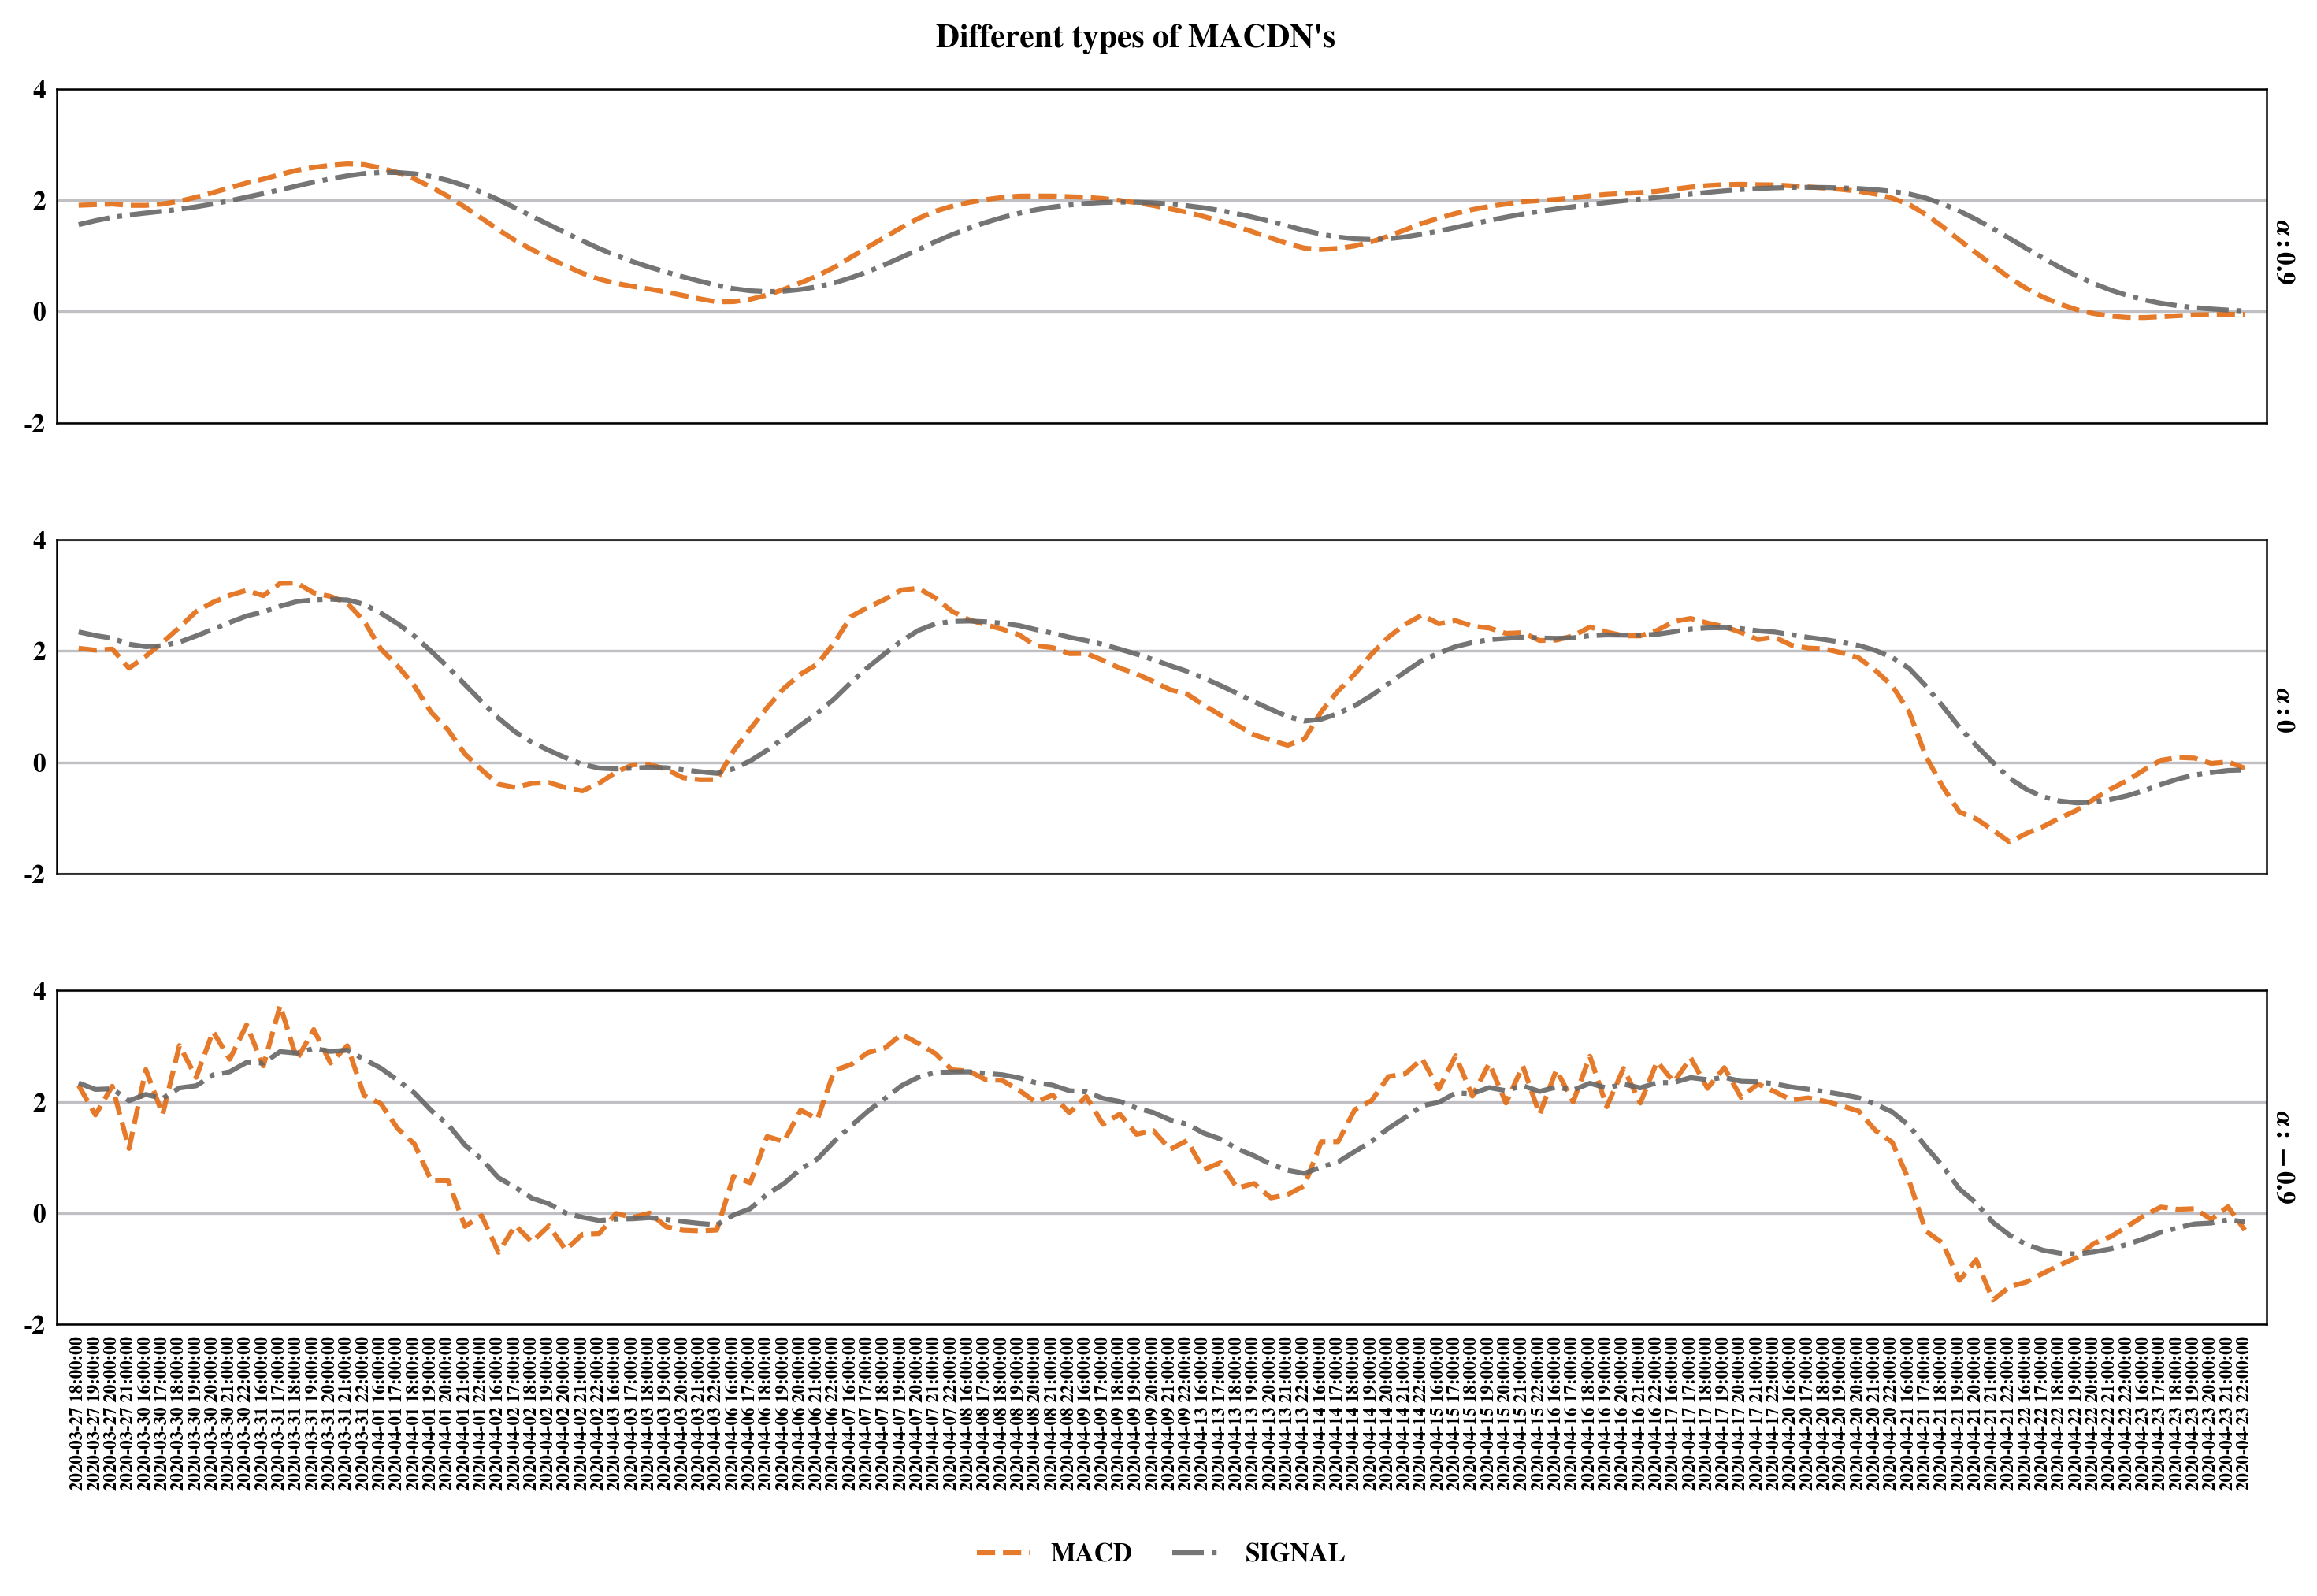

In [37]:
fig, axex = plt.subplots(nrows=3, sharex=True)
target_his_modes = ["Histogram a: 0.9", "Histogram", "Histogram a: -0.9"]
for his_index, his_mode in enumerate(target_his_modes):
    plot_macds_subplot(
        his_mode, df_subset, histogramList, prices, axex[his_index], ind, his_index
    )

# fb

plt.rcParams["font.weight"] = "bold"
fig.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0.35)
# fig.supylabel('Price ($)', fontweight='bold', color='black', fontsize=8)
fig.suptitle(
    "Different types of MACDN's", y=1, fontweight="bold", fontsize=10, color="black"
)
fig.set_size_inches(10, 7)
plt.savefig(f"Three_MACD.pdf", bbox_inches="tight")

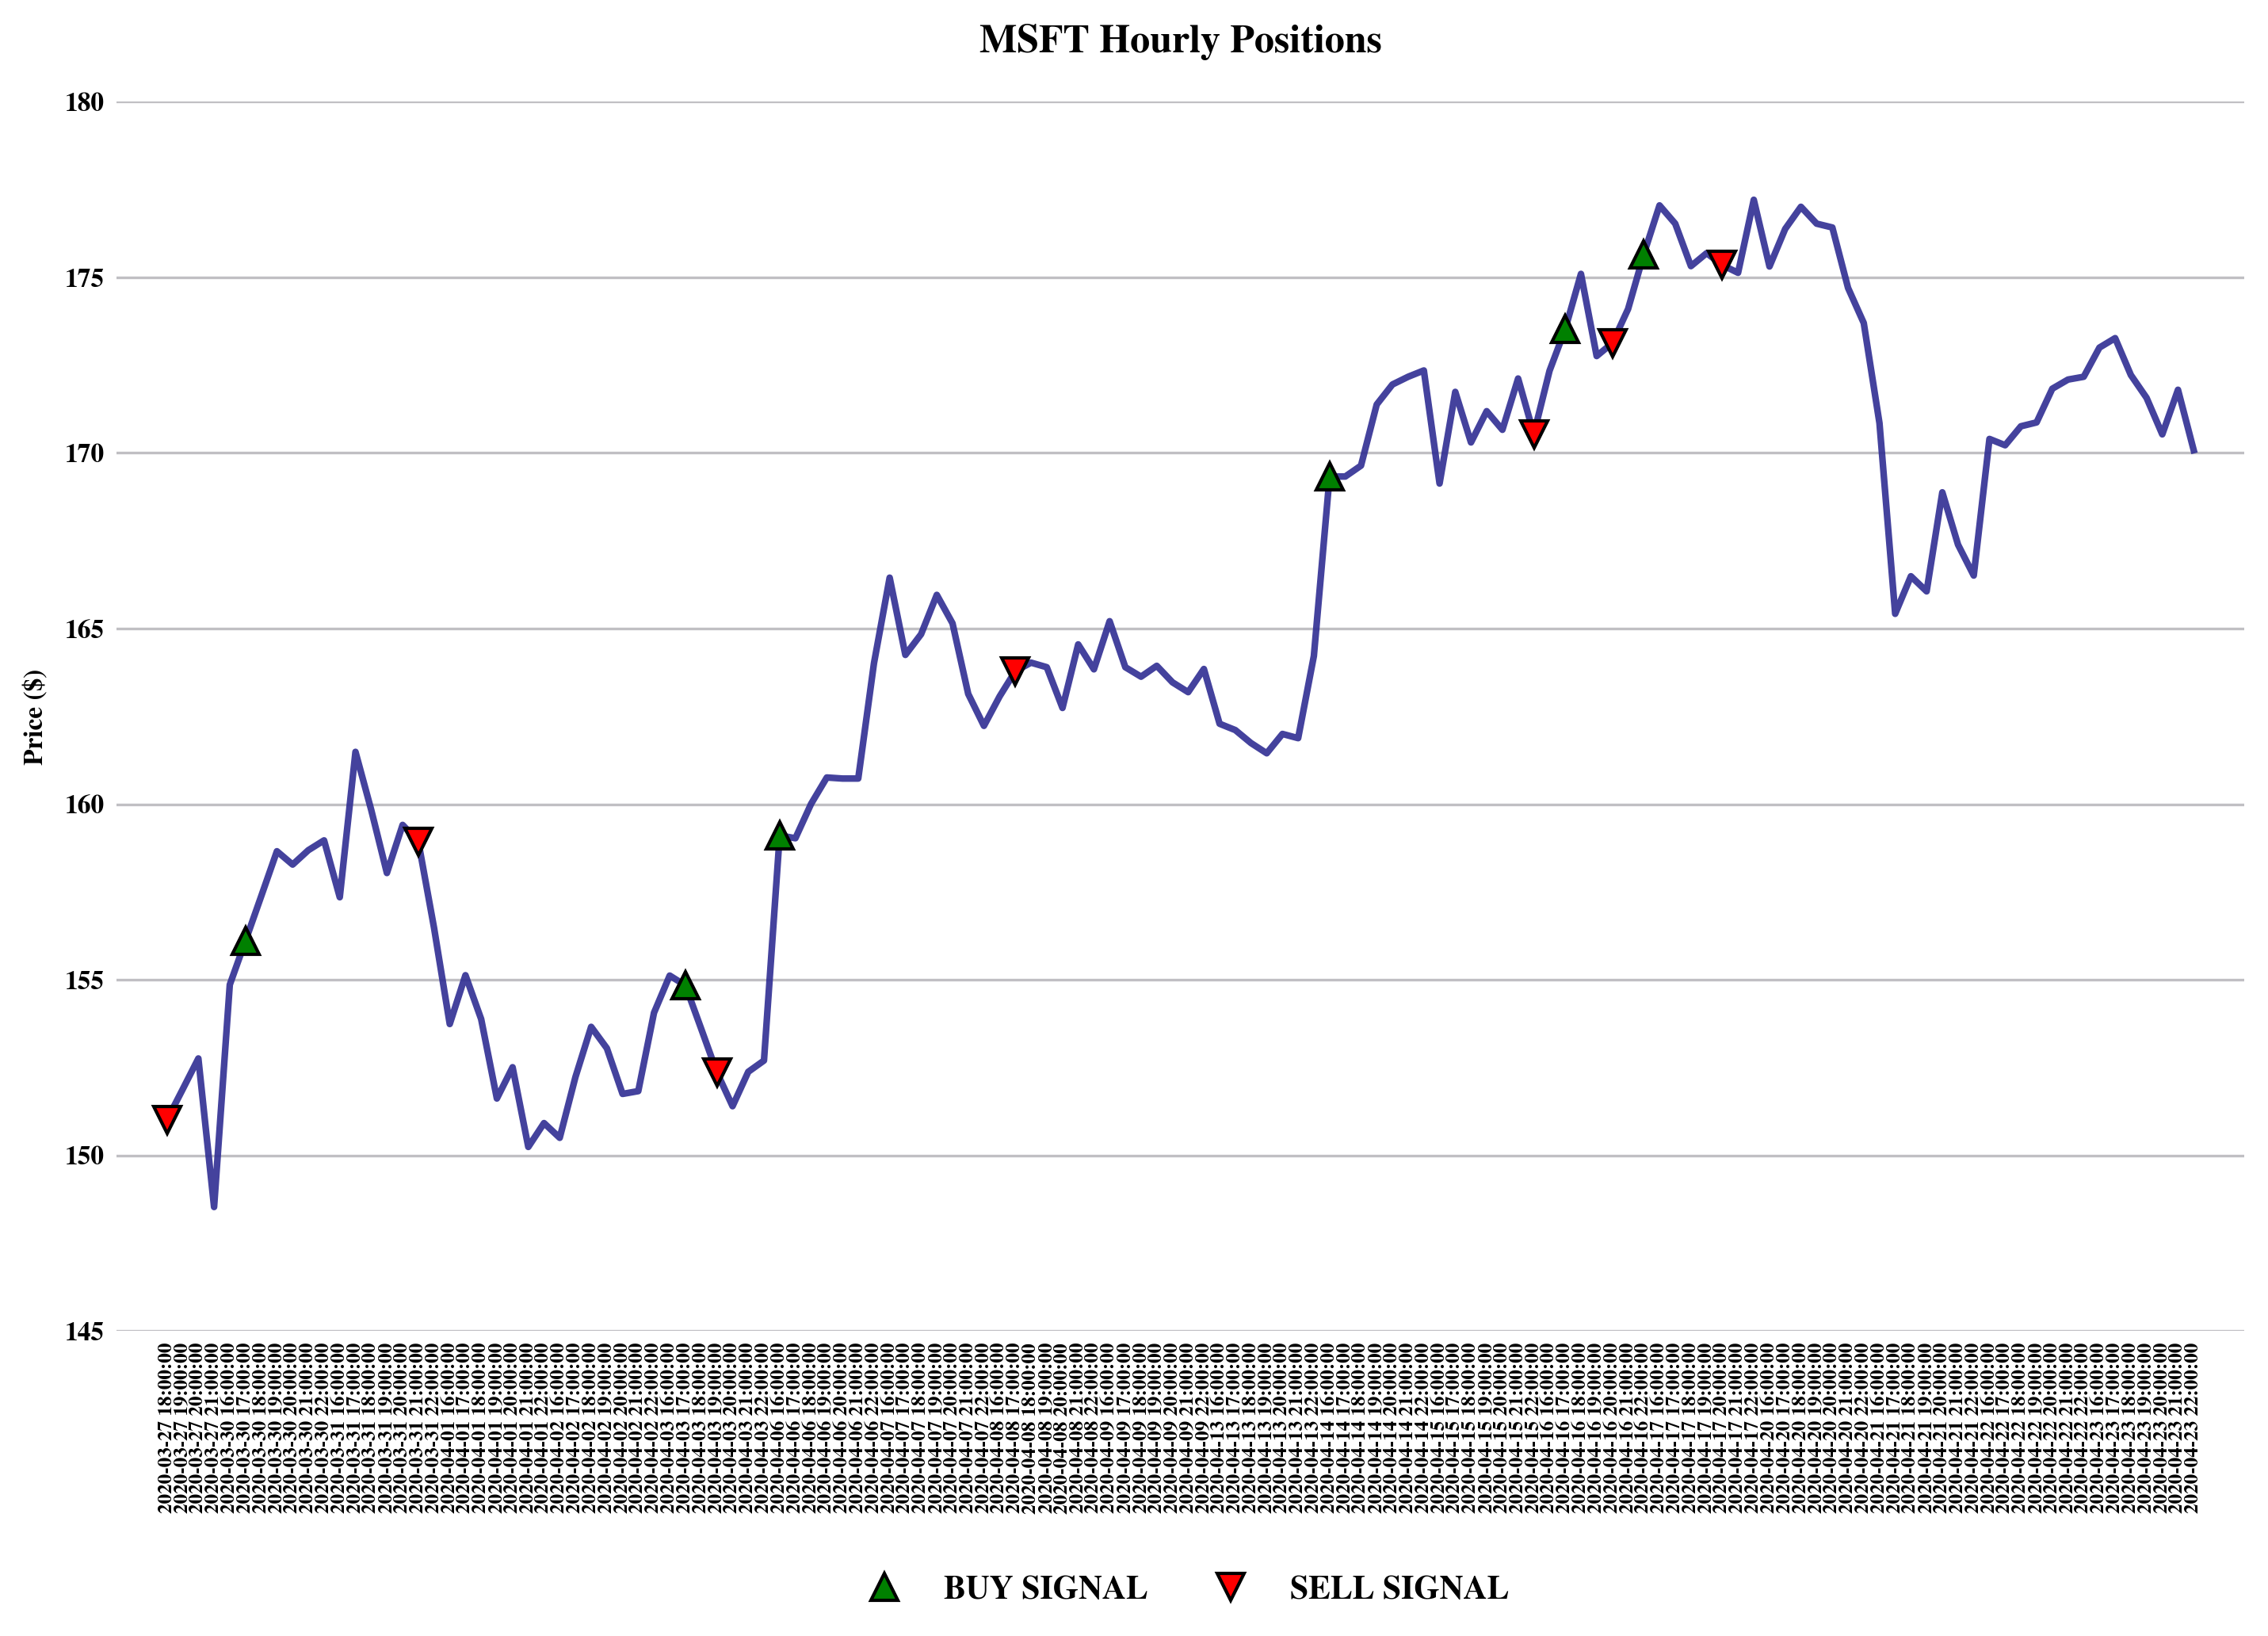

In [38]:
fig, ax = plt.subplots()
his_mode = "Histogram"

macd, signal, hist = return_macdn_data_for_plot(his_mode, df_subset)
dff, bets = return_macd_crossover_results(histogramList, df_subset, timeFormat, market)
buy_price, sell_price = get_actions_prices(bets, his_mode, df_subset)

ax.plot(ind, prices, color="#2f2d92", alpha=0.9)
ax.plot(
    ind,
    buy_price,
    marker="^",
    color="green",
    markersize=8,
    label="BUY SIGNAL",
    linewidth=0,
)
ax.plot(
    ind,
    sell_price,
    marker="v",
    color="r",
    markersize=8,
    label="SELL SIGNAL",
    linewidth=0,
)

ax.ticklabel_format(axis="y", style="plain")

ax.set_ylabel("Price ($)", fontweight="bold", fontsize=8, labelpad=5)

ax.xaxis.set_ticks(ind)
ax.set_xticklabels(ind, weight="bold", color="black")

avg_y_ticks = list(ax.get_yticks())
if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = int(avg_y_ticks[i])
else:
    for i in range(len(avg_y_ticks)):
        avg_y_ticks[i] = round(avg_y_ticks[i], 1)

ax.yaxis.set_ticks(avg_y_ticks)
ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

plt.rcParams["font.weight"] = "bold"

ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.set_axisbelow(True)
ax.tick_params(axis="both", which="both", length=0)
plt.xticks(rotation=90)

# ax.xaxis.grid(alpha = 0.15)
ax.yaxis.grid(alpha=0.8)

ax.margins(0.025)

fig.tight_layout()

fig.set_size_inches(10, 7)

ax.legend(
    labelcolor="black",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    frameon=False,
)
t = ax.set_title(
    f"{tick_dict[tick]} {timeFormat} Positions",
    loc="center",
    pad=15,
    size=12,
    fontweight="bold",
    color="black",
)

In [39]:
# ['Histogram', 'Histogram a: -0.9', 'Histogram a: -0.5', 'Histogram a: -0.4', 'Histogram a: -0.3',
# 'Histogram a: -0.2', 'Histogram a: -0.1', 'Histogram a: 0', 'Histogram a: 0.1', 'Histogram a: 0.2',
# 'Histogram a: 0.3', 'Histogram a: 0.4', 'Histogram a: 0.5', 'Histogram a: 0.9', 'Histogram a: -0.9 g: 10',
# 'Histogram a: -0.9 g: 100', 'Histogram a: -0.5 g: 10', 'Histogram a: -0.5 g: 100', 'Histogram a: -0.4 g: 10',
# 'Histogram a: -0.4 g: 100', 'Histogram a: -0.3 g: 10', 'Histogram a: -0.3 g: 100',
# 'Histogram a: -0.2 g: 10', 'Histogram a: -0.2 g: 100', 'Histogram a: -0.1 g: 10',
# 'Histogram a: -0.1 g: 100', 'Histogram a: 0 g: 10', 'Histogram a: 0 g: 100',
# 'Histogram a: 0.1 g: 10', 'Histogram a: 0.1 g: 100', 'Histogram a: 0.2 g: 10',
# 'Histogram a: 0.2 g: 100', 'Histogram a: 0.3 g: 10', 'Histogram a: 0.3 g: 100',
# 'Histogram a: 0.4 g: 10', 'Histogram a: 0.4 g: 100', 'Histogram a: 0.5 g: 10',
# 'Histogram a: 0.5 g: 100', 'Histogram a: 0.9 g: 10', 'Histogram a: 0.9 g: 100']

In [42]:
def get_actions_prices(bets_dict, his_mode, current_df):
    # print(his_mode)
    position_prices, actions = [bet[0] for bet in bets_dict[his_mode]], [
        bet[1] for bet in bets_dict[his_mode]
    ]
    close_data_list = list(current_df["close"])

    buy_price = [np.nan for i in range(len(close_data_list))]
    sell_price = [np.nan for i in range(len(close_data_list))]

    for i in range(0, len(actions), 2):
        position_mode = actions[i].split(" ")[1]
        price_index = close_data_list.index(position_prices[i])

        if position_mode == "Long":
            buy_price[price_index] = position_prices[i]
        else:
            sell_price[price_index] = position_prices[i]

    return buy_price, sell_price


def plot_price_subplot(
    his_mode,
    df_subset,
    histogramList,
    data_price,
    ax,
    ind,
    timeFormat,
    market,
    axIndex=None,
):
    macd, signal, hist = return_macdn_data_for_plot(his_mode, df_subset)
    dff, bets = return_macd_crossover_results(
        histogramList, df_subset, timeFormat, market
    )
    # print(bets)
    buy_price, sell_price = get_actions_prices(bets, his_mode, df_subset)

    ax.plot(ind, data_price, color="#2f2d92", alpha=0.9)
    ax.plot(
        ind,
        buy_price,
        marker="^",
        color="green",
        markersize=6,
        label="BUY SIGNAL",
        linewidth=0,
    )
    ax.plot(
        ind,
        sell_price,
        marker="v",
        color="r",
        markersize=6,
        label="SELL SIGNAL",
        linewidth=0,
    )

    ax.ticklabel_format(axis="y", style="plain")

    if axIndex == 3:
        ax.set_ylabel("Price ($)", fontweight="bold", fontsize=10, labelpad=5)

    if axIndex == 6:
        ax.xaxis.set_ticks(ind)
        ax.set_xticklabels(ind, weight="bold", color="black", fontsize=5.5)

    avg_y_ticks = list(ax.get_yticks())
    if ((avg_y_ticks[1] - avg_y_ticks[0]) % 1) == 0:
        for i in range(len(avg_y_ticks)):
            avg_y_ticks[i] = int(avg_y_ticks[i])
    else:
        for i in range(len(avg_y_ticks)):
            avg_y_ticks[i] = round(avg_y_ticks[i], 1)

    ax.yaxis.set_ticks(avg_y_ticks)
    ax.set_yticklabels(avg_y_ticks, weight="bold", color="black")
    ax.set_ylim(avg_y_ticks[0], avg_y_ticks[-1])

    # ax.spines["left"].set_visible(False)
    # ax.spines["right"].set_visible(True)
    # ax.spines["bottom"].set_visible(False)
    # # mpl.rcParams['axes.linewidth'] = 3
    ax.spines["right"].set_visible(True)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["top"].set_visible(True)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", which="both", length=0)
    plt.xticks(rotation=90)

    # ax.xaxis.grid(alpha = 0.15)
    ax.yaxis.grid(alpha=0.8)

    ax.margins(0.025)

    if axIndex == 6:
        ax.legend(
            labelcolor="black",
            loc="upper center",
            bbox_to_anchor=(0.5, -1.5),
            ncol=2,
            frameon=False,
            fontsize=8,
        )

    # increasing y makes it go up, decreasing y makes it go down
    if his_mode == "Histogram":
        his_title = r"$\alpha: 0$"
        t = ax.set_title(
            f"{his_title}",
            loc="right",
            y=0.22,
            size=6,
            x=1.0125,
            fontweight="bold",
            color="black",
            rotation=-90,
        )

    else:

        his_words = his_mode.split(" ")

        if len(his_words) == 5:  # MACDN2

            if float(his_words[2]) > 0:  # a > 0

                if int(his_words[4]) == 10:  # g = 10
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.062,
                        size=6,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

                else:  # g = 100
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.12,
                        size=6,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

            else:  # a < 0

                if int(his_words[4]) == 10:  # g = 10
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.117,
                        size=5.5,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

                else:  # g = 100
                    his_title = (
                        r"$\alpha: "
                        + his_words[2]
                        + r"\; , \;"
                        + r" \gamma: "
                        + his_words[4]
                        + "$"
                    )
                    t = ax.set_title(
                        f"{his_title}",
                        loc="right",
                        y=-0.115,
                        size=5,
                        x=1.0125,
                        fontweight="bold",
                        color="black",
                        rotation=-90,
                    )

        else:  # MACDN1

            if float(his_words[2]) > 0:
                his_title = r"$\alpha: " + his_words[2] + "$"
                t = ax.set_title(
                    f"{his_title}",
                    loc="right",
                    y=0.1,
                    size=6,
                    x=1.0125,
                    fontweight="bold",
                    color="black",
                    rotation=-90,
                )

            else:
                his_title = r"$\alpha: " + his_words[2] + "$"
                t = ax.set_title(
                    f"{his_title}",
                    loc="right",
                    y=0.05,
                    size=6,
                    x=1.0125,
                    fontweight="bold",
                    color="black",
                    rotation=-90,
                )

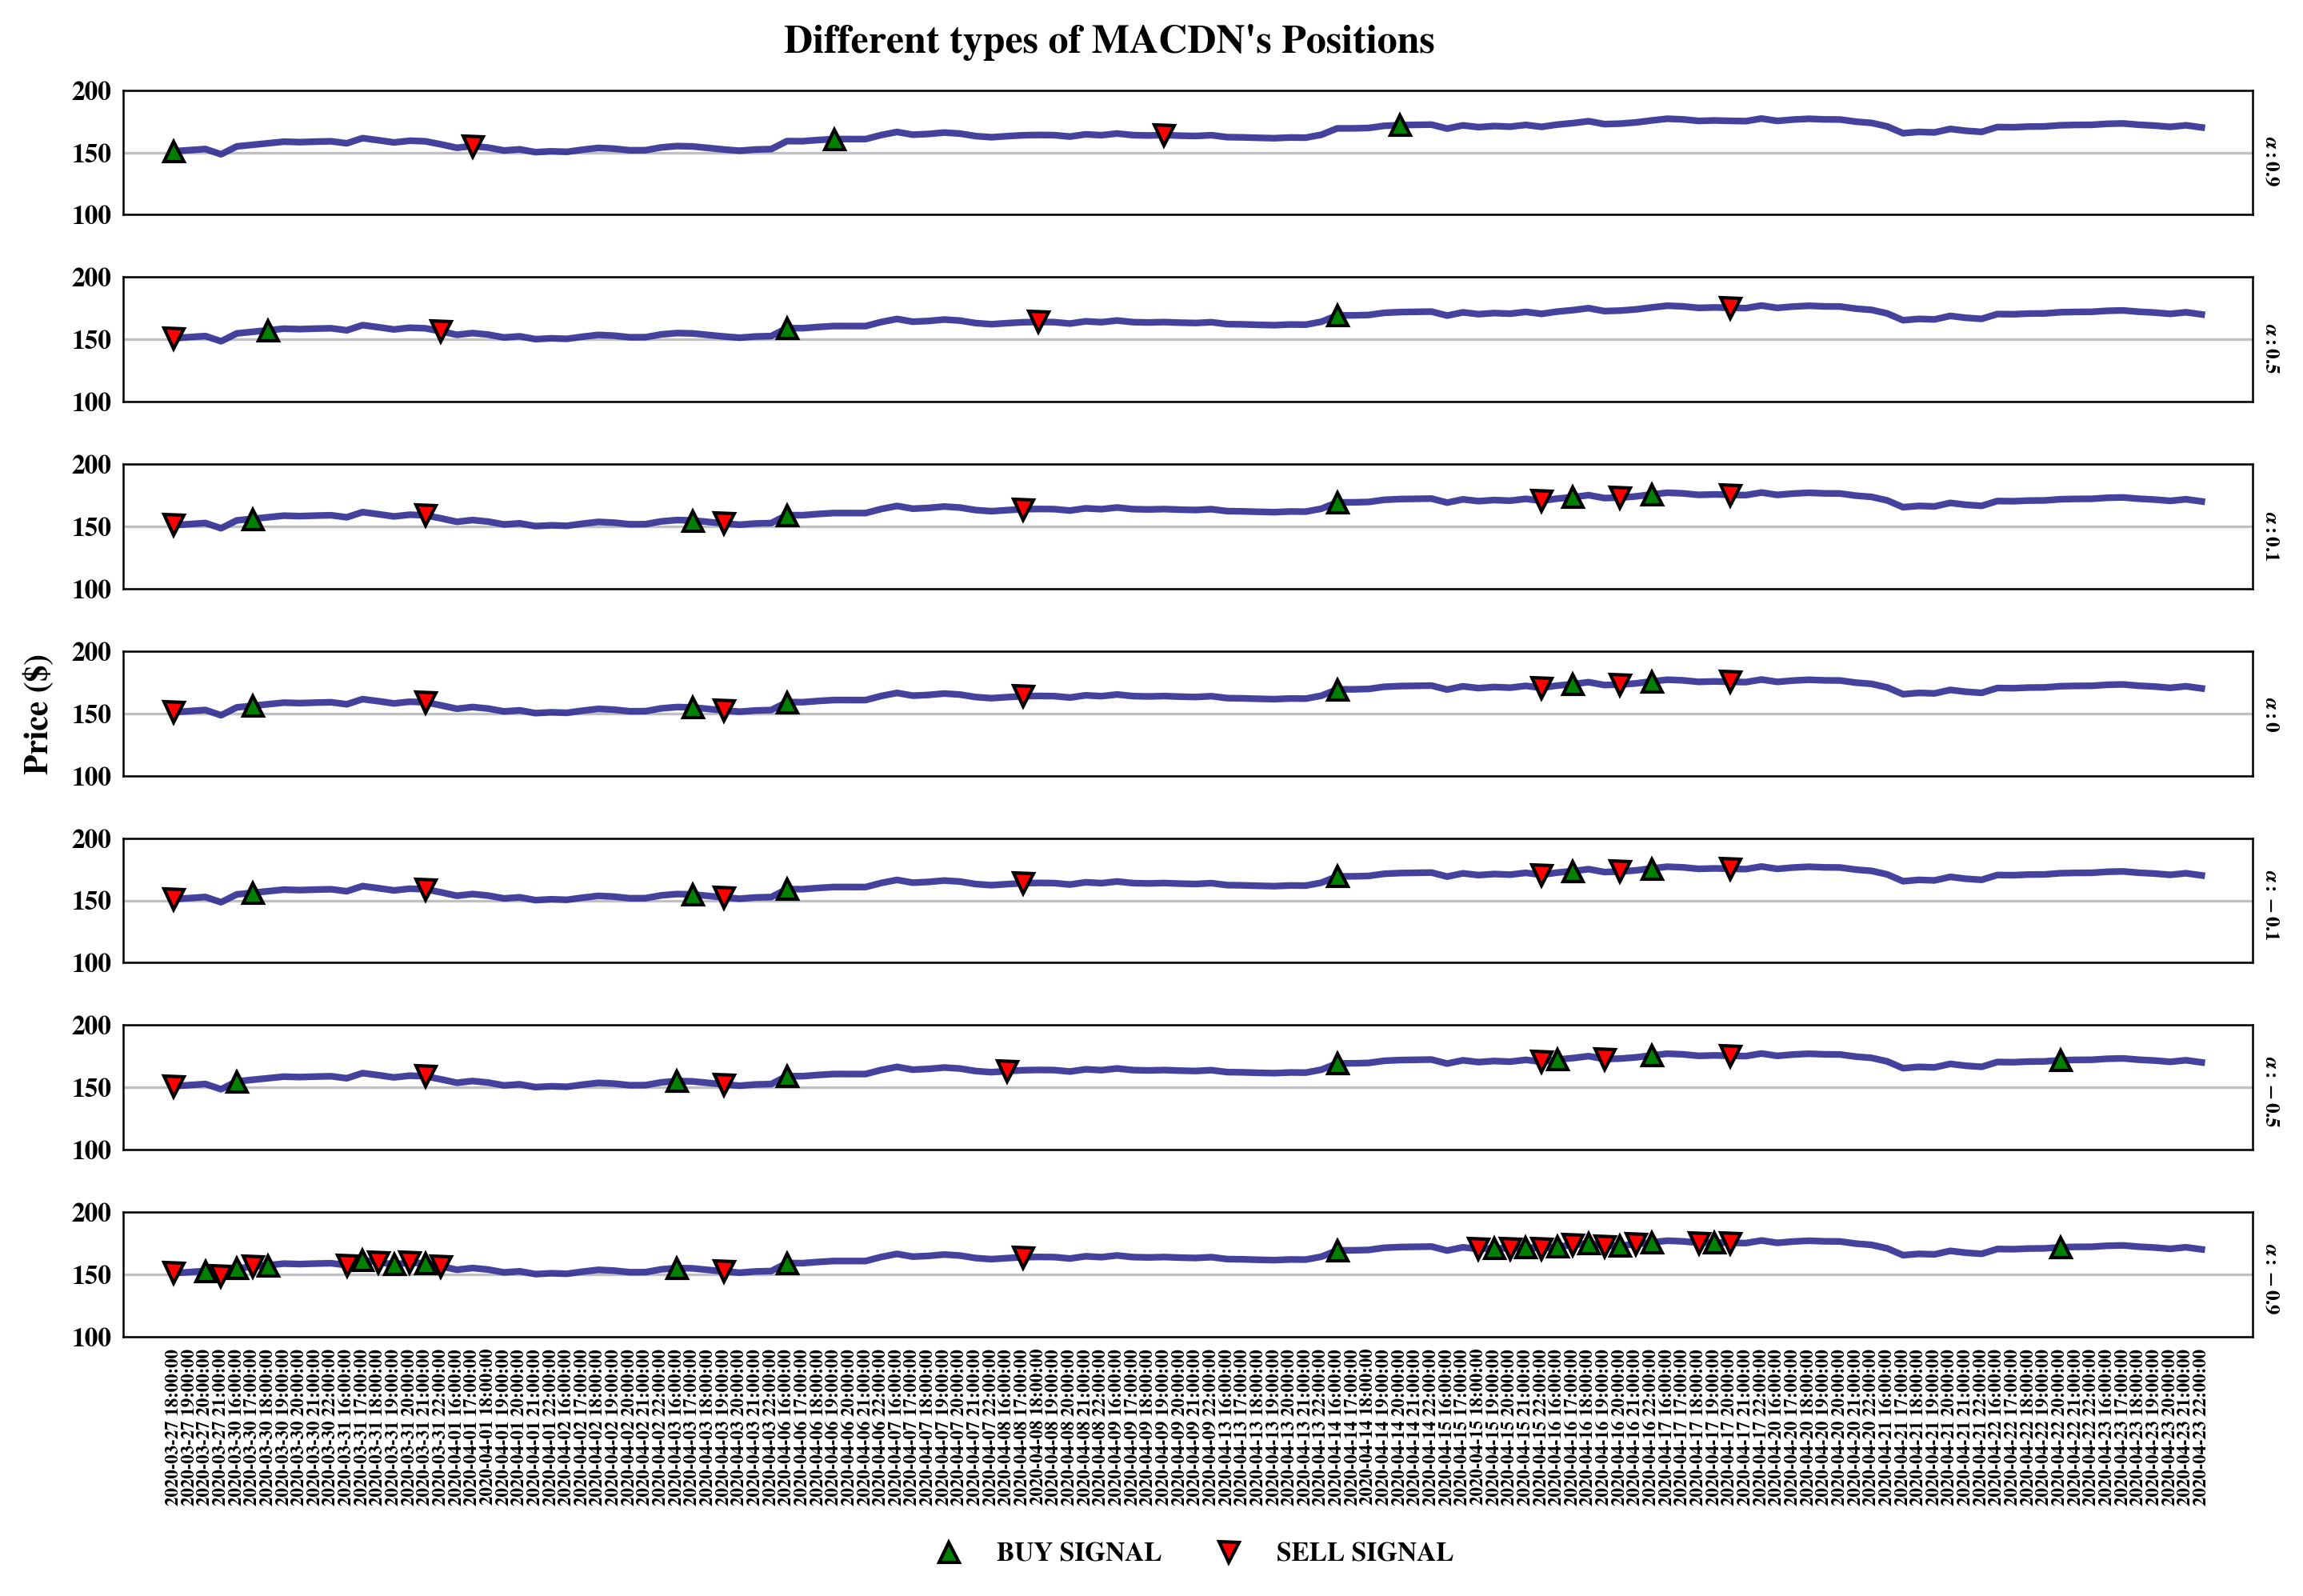

In [43]:
fig, axex = plt.subplots(nrows=7, sharex=True)

# msft


target_his_modes = [
    "Histogram a: 0.9",
    "Histogram a: 0.5",
    "Histogram a: 0.1",
    "Histogram",
    "Histogram a: -0.1",
    "Histogram a: -0.5",
    "Histogram a: -0.9",
]
for his_index, his_mode in enumerate(target_his_modes):
    plot_price_subplot(
        his_mode,
        df_subset,
        histogramList,
        prices,
        axex[his_index],
        ind,
        timeFormat,
        market,
        his_index,
    )

plt.rcParams["font.weight"] = "bold"
fig.tight_layout()
plt.subplots_adjust(wspace=0, hspace=0.5)
# fig.supylabel('Price ($)', fontweight='bold', color='black', fontsize=8)
fig.suptitle(
    "Different types of MACDN's Positions",
    y=1,
    fontweight="bold",
    fontsize=12,
    color="black",
)
fig.set_size_inches(10, 7)
plt.savefig(f"Nine_MACD.pdf", bbox_inches="tight")